# Crop ROI — Horizontal Bounds

Goal: find fixed `x_start` / `x_end` pixel columns that crop out the black surround and patient-data text panel from endoscopy frames, so the crop can be hardcoded into the pipeline (see `Decision_Log.md`).

Two parts:
1. **Manual exploration** — inspect one sample frame's brightness profile by hand to understand where the edge actually sits, before automating anything.
2. **Two independent detection methods**, run across real videos, to derive and cross-validate the final fixed bounds.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob


In [37]:
# ---------- CONFIG ----------
image_path = "C:/Users/ahmed/Documents/Jobs/Klinikum Oldenburg/sample_frames/frame_0388.png"
scan_row_frac = 0.60

In [38]:
# ---------- LOAD ----------
frame = cv2.imread(image_path)
if frame is None:
    raise FileNotFoundError(f"Could not read image at: {image_path}")

h, w = frame.shape[:2]
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
row_y = int(h * scan_row_frac)
row = gray[row_y, :]

print(f"Image size: {w} x {h}")
print(f"Scanning row y = {row_y} ({scan_row_frac*100:.0f}% down)")
print(f"Row stats -> min: {row.min()}  max: {row.max()}  mean: {row.mean():.1f}")

Image size: 1920 x 1080
Scanning row y = 648 (60% down)
Row stats -> min: 12  max: 179  mean: 75.3


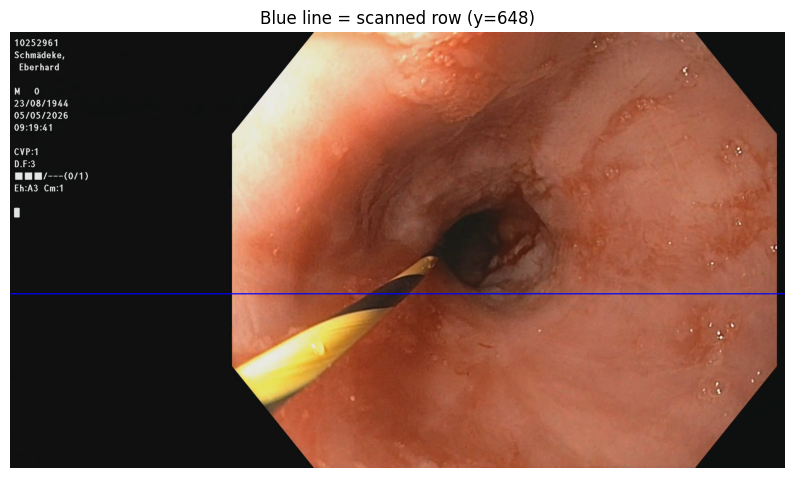

In [39]:
# ---------- SHOW WHERE THE ROW SITS ON THE ACTUAL IMAGE ----------
vis = frame.copy()
cv2.line(vis, (0, row_y), (w - 1, row_y), (255, 0, 0), 2)
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"Blue line = scanned row (y={row_y})")
plt.axis("off")
plt.show()


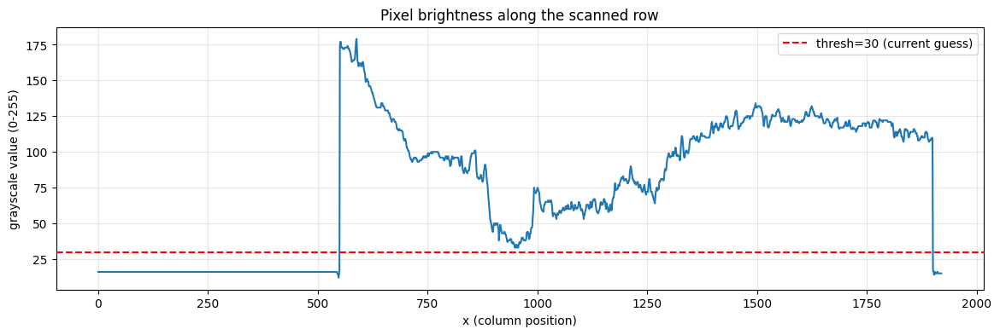

In [40]:
# ---------- PLOT BRIGHTNESS ALONG THE ROW ----------
plt.figure(figsize=(14, 4))
plt.plot(row)
plt.axhline(30, color="red", linestyle="--", label="thresh=30 (current guess)")
plt.title("Pixel brightness along the scanned row")
plt.xlabel("x (column position)")
plt.ylabel("grayscale value (0-255)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [50]:
# ---------- RAW VALUES, CLOSE UP ON EACH EDGE ----------
n = 100  # how many pixels to print near each edge

print(f"\nFirst {n} pixel values (left edge region), x=0..{n-1}:")
print(row[5*n:6*n])

print()
print(row[542])
print(row[543])
print(row[544]) #
print(row[545])
print(row[546])
print(row[550])


First 100 pixel values (left edge region), x=0..99:
[ 16  16  16  16  16  16  16  16  16  16  16  16  16  16  16  16  16  16
  16  16  16  16  16  16  16  16  16  16  16  16  16  16  16  16  16  16
  16  16  16  16  16  16  16  16  15  15  14  12  14  17 174 177 177 174
 173 173 173 172 172 172 172 173 173 173 173 173 173 174 174 173 172 172
 171 170 169 167 165 163 163 164 164 164 164 165 165 169 174 178 179 172
 164 163 160 160 162 162 162 162 160 160]

16
16
15
15
14
174


In [51]:
print(f"\nLast {n} pixel values (right edge region), x={w-n}..{w-1}:")
print(row[-n:])

print()
print(row[1909])
print(row[1910])
print(row[1911]) #
print(row[1912])
print(row[1913])
print(row[1899])



Last 100 pixel values (right edge region), x=1820..1919:
[114 113 114 115 115 116 115 113 111 111 110 109 108 107 109 113 116 115
 115 116 115 115 115 114 111 110 111 113 113 114 114 114 114 114 114 114
 116 116 115 115 114 113 113 113 111 111 108 108 108 108 109 109 110 110
 111 111 111 110 110 110 110 110 113 114 114 114 113 113 110 109 108 107
 108 108 108 109 109 109 110 108  18  16  15  14  16  16  15  15  15  15
  16  16  15  15  15  15  15  15  15  15]

15
16
16
15
15
108


### Method 1 — Fixed threshold + sustained run

Scans a row (below the text panel) from each side. A pixel counts as "content" if it's brighter than a fixed threshold (`color_thresh`). To avoid a single noisy pixel triggering a false edge, requires `min_run` consecutive above-threshold pixels before accepting it as the real boundary. Run across a folder of videos, sampling a few evenly-spaced frames per video.


Found 8 video(s)

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O983C19_12-06-25_101337.mp4
  10 evenly spaced: [0, 75, 150, 226, 301, 377, 452, 527, 603, 678]
  middle 2 used:    [301, 377]
  frame 301: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


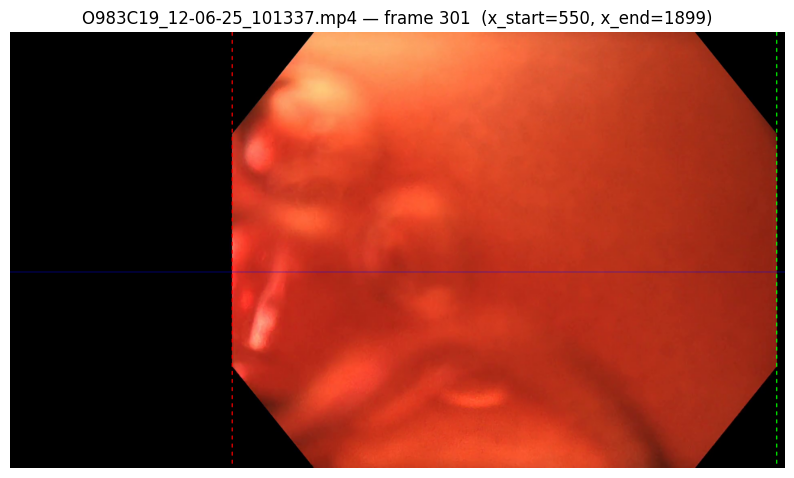

  frame 377: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


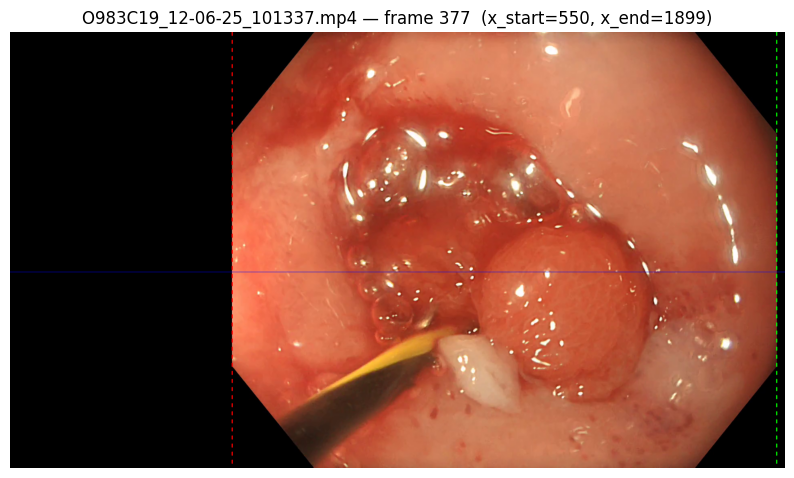

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O983C20_12-06-25_101352.mp4
  10 evenly spaced: [0, 39, 78, 117, 156, 195, 234, 273, 312, 351]
  middle 2 used:    [156, 195]
  frame 156: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


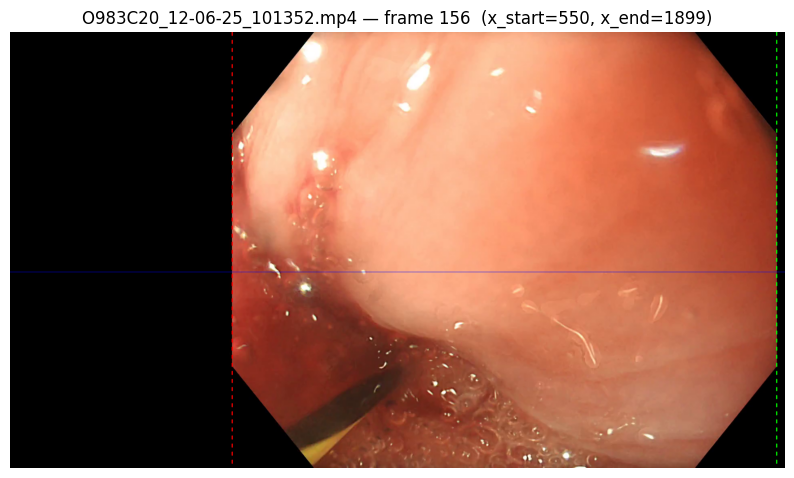

  frame 195: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


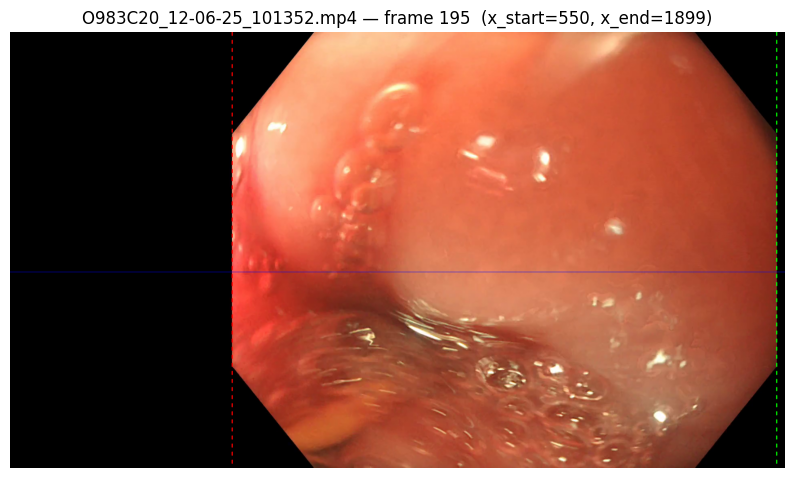

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O99242D_11-07-25_093158.mp4
  10 evenly spaced: [0, 119, 239, 359, 478, 598, 718, 837, 957, 1077]
  middle 2 used:    [478, 598]
  frame 478: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


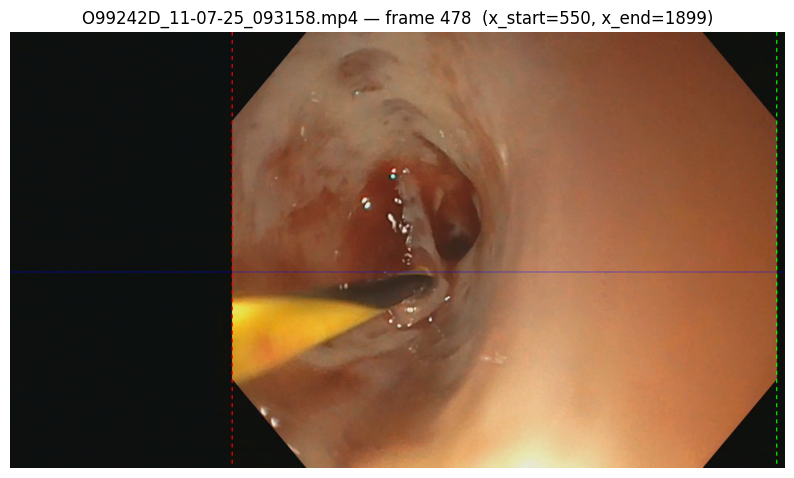

  frame 598: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


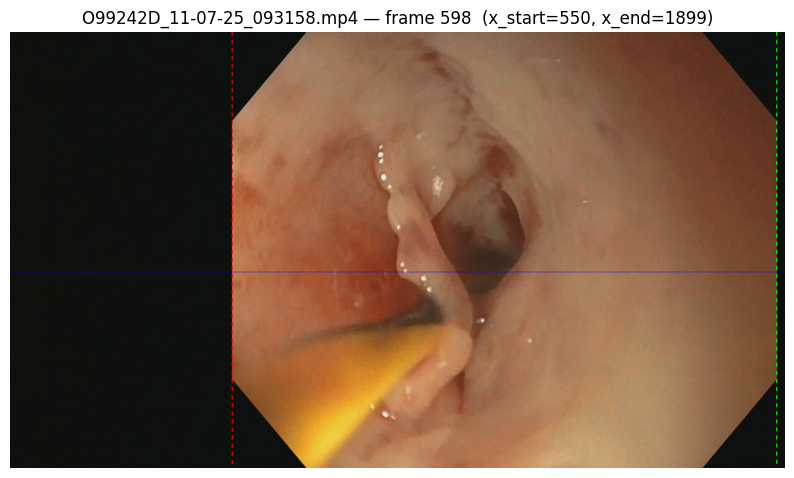

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O9C3E27_24-10-25_090146.mp4
  10 evenly spaced: [0, 23, 47, 71, 95, 119, 143, 167, 191, 215]
  middle 2 used:    [95, 119]
  frame 95: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


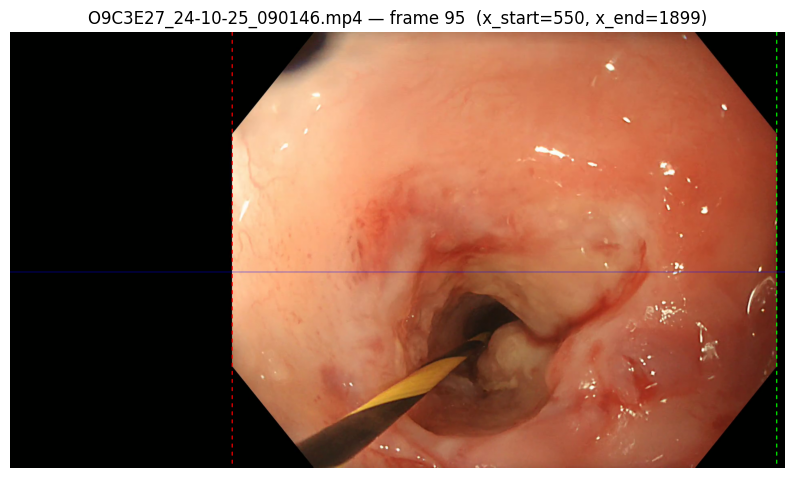

  frame 119: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


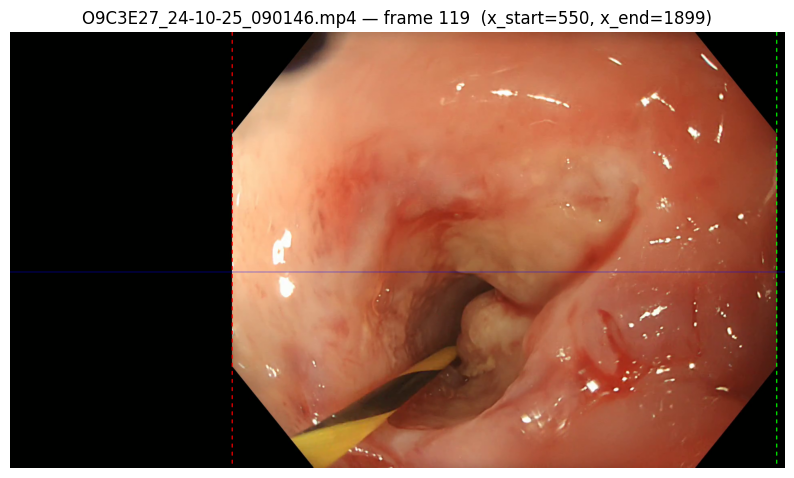

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O9E3CEC_07-01-26_092102.mp4
  10 evenly spaced: [0, 171, 343, 514, 686, 858, 1029, 1201, 1372, 1544]
  middle 2 used:    [686, 858]
  frame 686: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


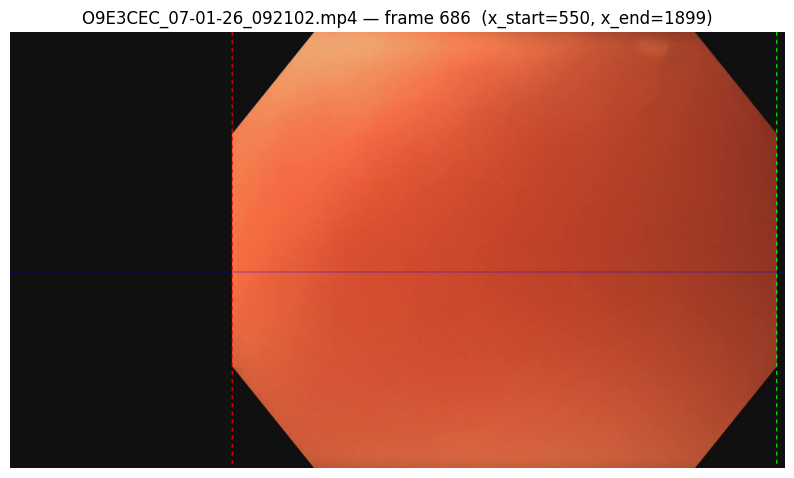

  frame 858: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


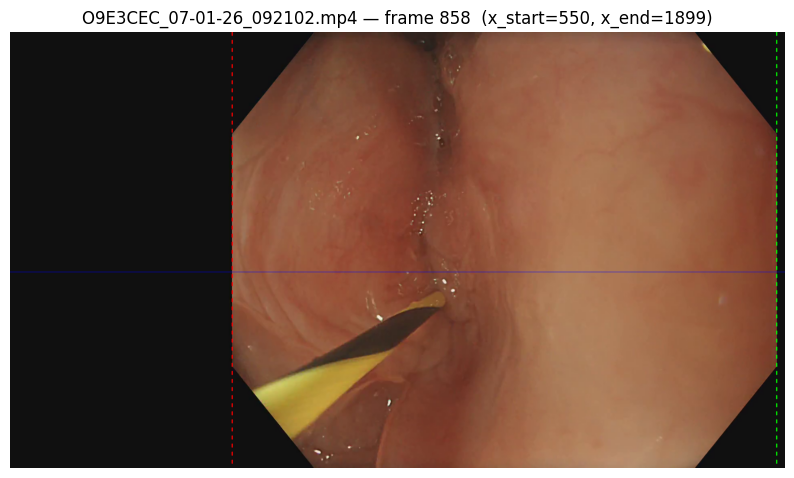

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA08324_23-03-26_102243.mp4
  10 evenly spaced: [0, 75, 150, 226, 301, 377, 452, 527, 603, 678]
  middle 2 used:    [301, 377]
  frame 301: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


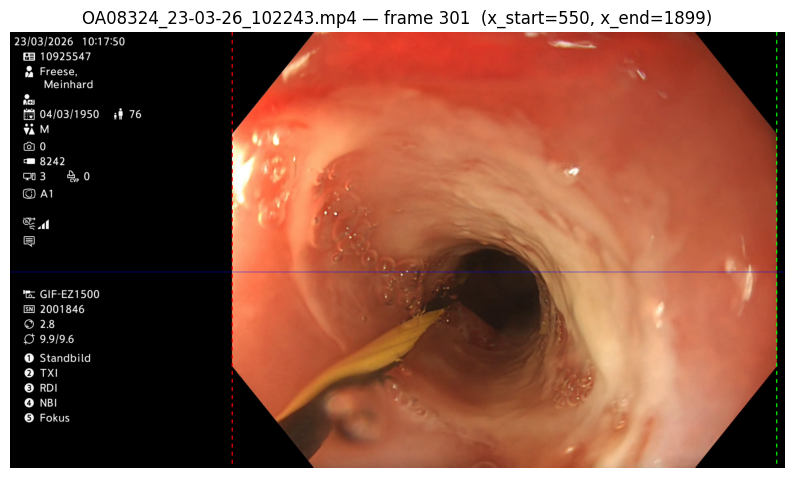

  frame 377: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


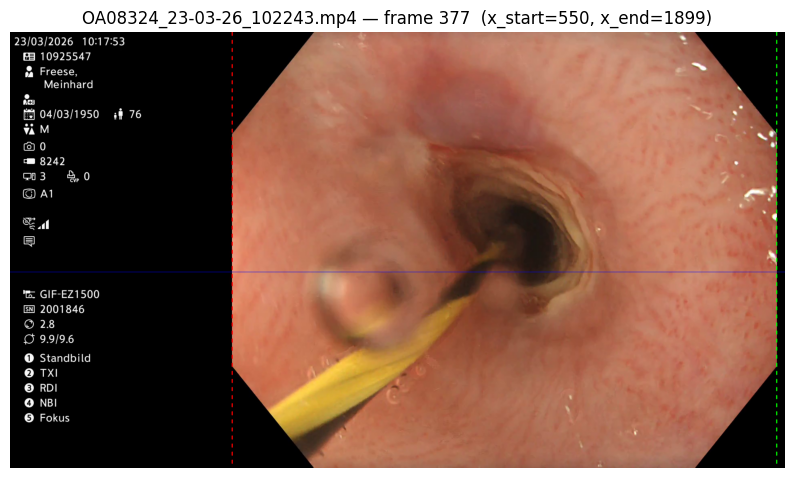

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA2459C_05-05-26_102237.mp4
  10 evenly spaced: [0, 109, 218, 327, 436, 545, 654, 763, 872, 981]
  middle 2 used:    [436, 545]
  frame 436: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


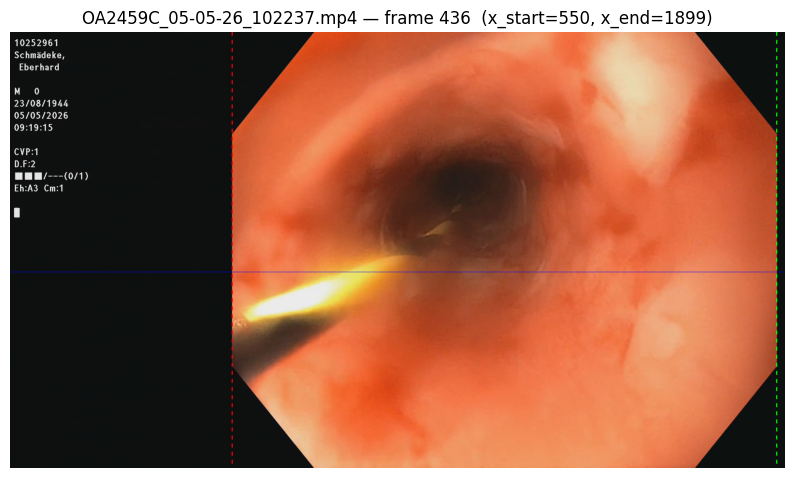

  frame 545: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


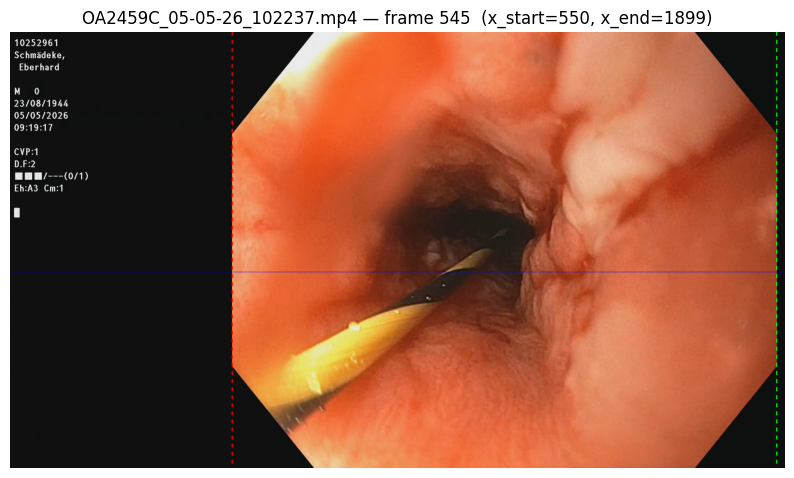

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA245A0_05-05-26_102303.mp4
  10 evenly spaced: [0, 129, 259, 388, 518, 647, 777, 906, 1036, 1165]
  middle 2 used:    [518, 647]
  frame 518: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


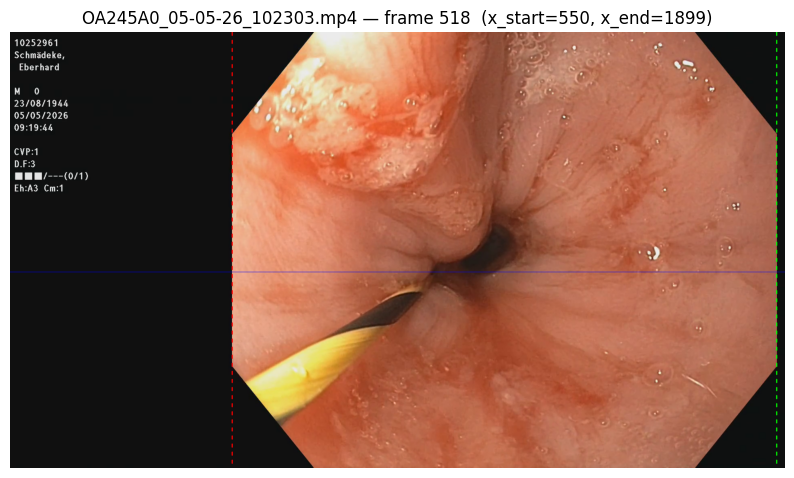

  frame 647: x_start=550  x_end=1899  (left margin=550px, right margin=20px)


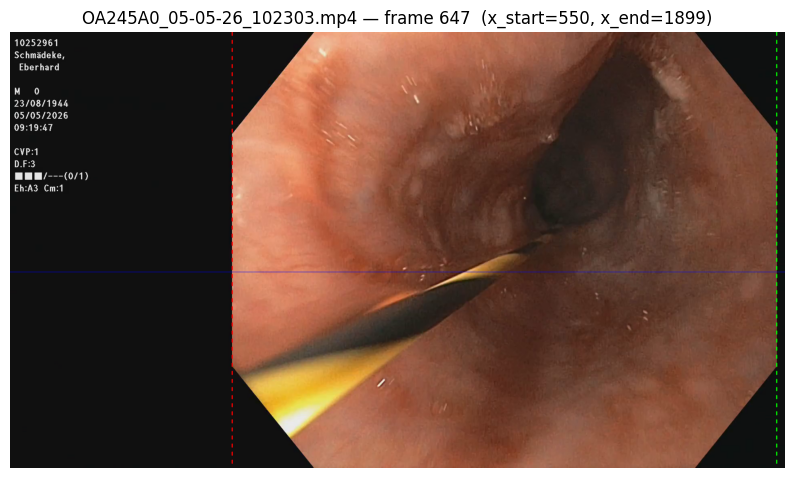


SUMMARY across all videos/frames
  x_start values: [550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550]
  x_end values:   [1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899]

  Safest fixed crop (never cuts content):
    x_start (leftmost observed)  = 550
    x_end   (rightmost observed) = 1899


In [46]:
# ---------- CONFIG ----------
video_folder = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos"
video_extensions = ("*.mp4", "*.avi", "*.mov", "*.mkv")

scan_row_frac = 0.55   # row position (fraction of height) to scan — below the text panel
color_thresh  = 30     # grayscale value above which a pixel counts as "content"
min_run       = 10     # consecutive above-threshold pixels required to accept an edge (avoids noise false-triggers)

# ---------- HELPERS ----------

def find_roi_horizontal_bounds(frame, scan_row_frac=0.60, thresh=30, min_run=15):
    h, w = frame.shape[:2]
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    row_y = int(h * scan_row_frac)
    row = gray[row_y, :]
    above = row > thresh

    x_start = None
    for x in range(w - min_run):
        if above[x:x + min_run].all():
            x_start = x
            break

    x_end = None
    for x in range(w - 1, min_run - 1, -1):
        if above[x - min_run + 1:x + 1].all():
            x_end = x
            break

    return x_start, x_end, row_y


def draw_dotted_vline(img, x, color=(0, 0, 255), thickness=2, gap=12, dash=8):
    h = img.shape[0]
    y = 0
    while y < h:
        y2 = min(y + dash, h)
        cv2.line(img, (x, y), (x, y2), color, thickness)
        y += dash + gap


def middle_n(indices, n=2):
    drop = len(indices) - n
    start_drop = drop // 2
    end_drop = drop - start_drop
    return indices[start_drop: len(indices) - end_drop]


# ---------- MAIN ----------

all_x_starts = []
all_x_ends = []

video_paths = []
for ext in video_extensions:
    video_paths.extend(glob.glob(os.path.join(video_folder, "**", ext), recursive=True))

print(f"Found {len(video_paths)} video(s)\n")

for video_path in video_paths:
    print("=" * 80)
    print("Video:", video_path)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("  Could not open — skipping")
        continue

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    if total_frames < 10:
        print(f"  Only {total_frames} frames — skipping")
        cap.release()
        continue

    frames_to_extract = [int(total_frames * i / 10) for i in range(10)]
    middle_frames = middle_n(frames_to_extract, 2)
    print(f"  10 evenly spaced: {frames_to_extract}")
    print(f"  middle 2 used:    {middle_frames}")

    for frame_idx in middle_frames:
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()
        if not ret:
            print(f"  frame {frame_idx}: could not read — skipping")
            continue

        x_start, x_end, row_y = find_roi_horizontal_bounds(
            frame, scan_row_frac=scan_row_frac, thresh=color_thresh, min_run=min_run
        )

        if x_start is None or x_end is None:
            print(f"  frame {frame_idx}: edge not found (x_start={x_start}, x_end={x_end}) — skipping")
            continue

        left_margin = x_start
        right_margin = width - 1 - x_end

        print(f"  frame {frame_idx}: x_start={x_start}  x_end={x_end}  "
              f"(left margin={left_margin}px, right margin={right_margin}px)")

        all_x_starts.append(x_start)
        all_x_ends.append(x_end)

        vis = frame.copy()
        draw_dotted_vline(vis, x_start, color=(0, 0, 255))   # red = left ROI bound
        draw_dotted_vline(vis, x_end, color=(0, 255, 0))     # green = right ROI bound
        cv2.line(vis, (0, row_y), (width - 1, row_y), (255, 0, 0), 1)  # blue = scan row used

        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.title(f"{os.path.basename(video_path)} — frame {frame_idx}  (x_start={x_start}, x_end={x_end})")
        plt.axis("off")
        plt.show()

    cap.release()

# ---------- SUMMARY ----------
print("\n" + "=" * 80)
print("SUMMARY across all videos/frames")
print(f"  x_start values: {all_x_starts}")
print(f"  x_end values:   {all_x_ends}")
if all_x_starts and all_x_ends:
    print(f"\n  Safest fixed crop (never cuts content):")
    print(f"    x_start (leftmost observed)  = {min(all_x_starts)}")
    print(f"    x_end   (rightmost observed) = {max(all_x_ends)}")

### Method 2 — Adaptive baseline + delta

Instead of a fixed global threshold, measures a local "black" baseline per frame/row (median of the first/last `baseline_window` pixels), then flags the edge as the first pixel that differs from that baseline by more than `delta_thresh`. Self-calibrating per frame rather than relying on one hardcoded number.


Found 8 video(s)

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O983C19_12-06-25_101337.mp4
  frame 301: x_start=550  x_end=1899  | left baseline=0  right baseline=0


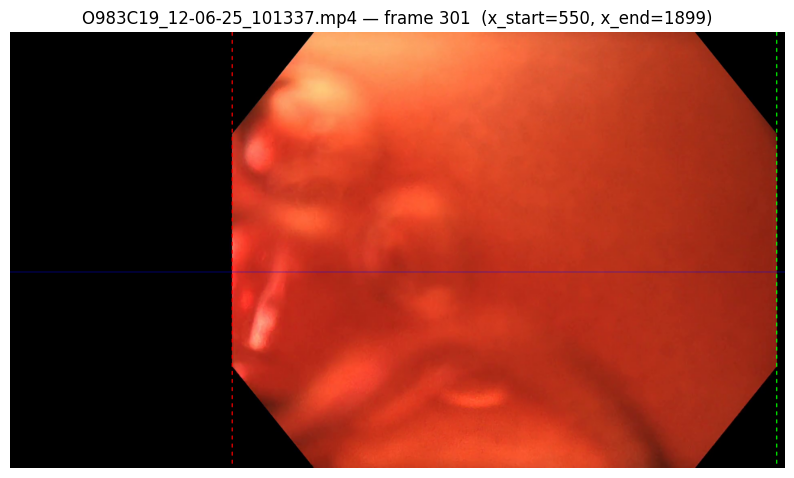

  frame 377: x_start=550  x_end=1899  | left baseline=0  right baseline=0


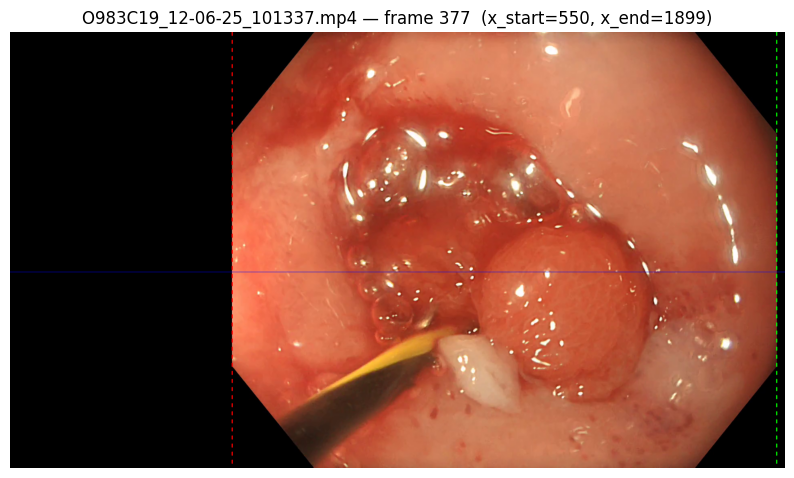

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O983C20_12-06-25_101352.mp4
  frame 156: x_start=550  x_end=1899  | left baseline=0  right baseline=0


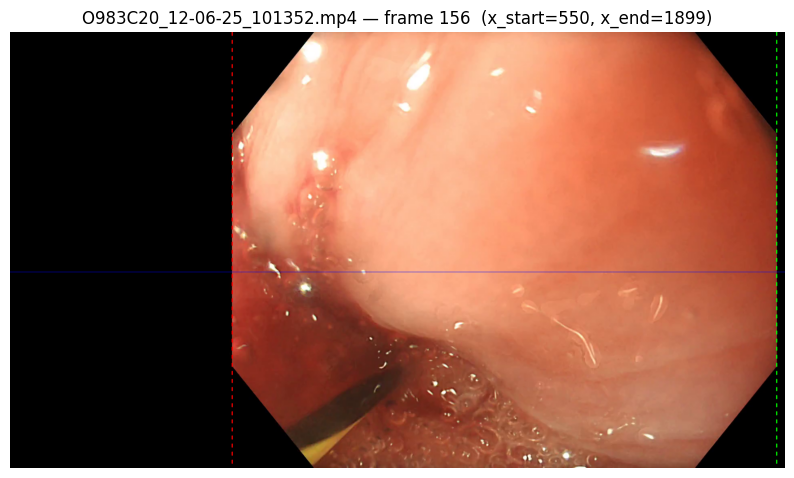

  frame 195: x_start=550  x_end=1899  | left baseline=0  right baseline=0


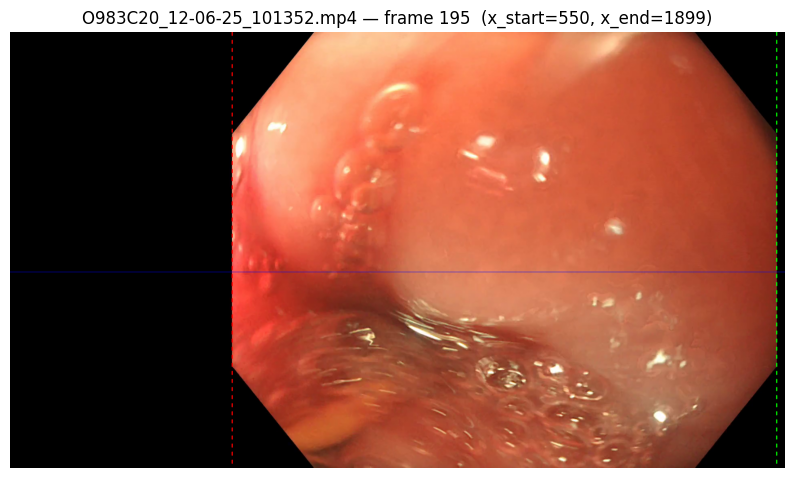

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O99242D_11-07-25_093158.mp4
  frame 478: x_start=550  x_end=1899  | left baseline=15  right baseline=15


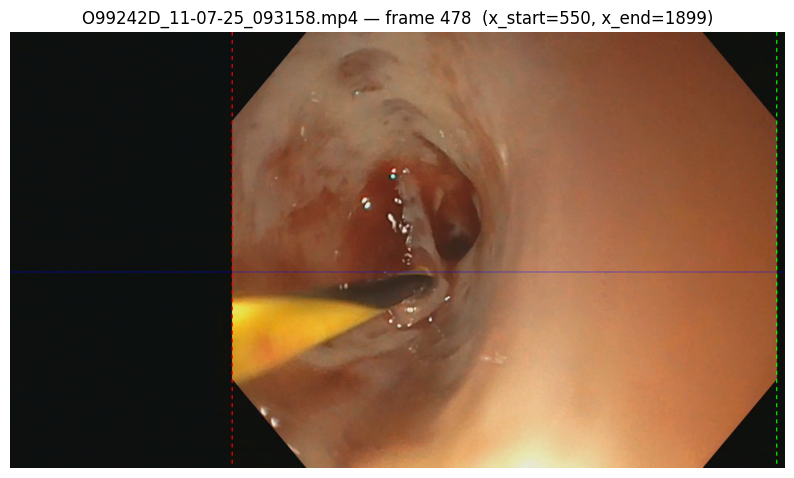

  frame 598: x_start=550  x_end=1899  | left baseline=16  right baseline=15


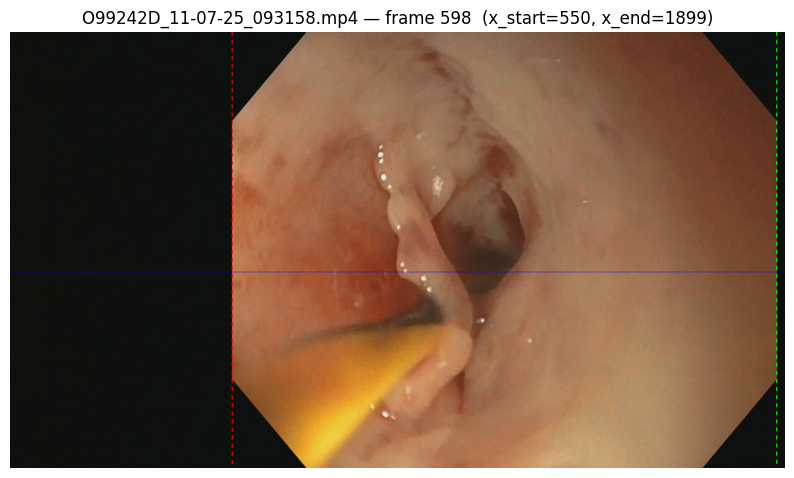

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O9C3E27_24-10-25_090146.mp4
  frame 95: x_start=550  x_end=1899  | left baseline=1  right baseline=1


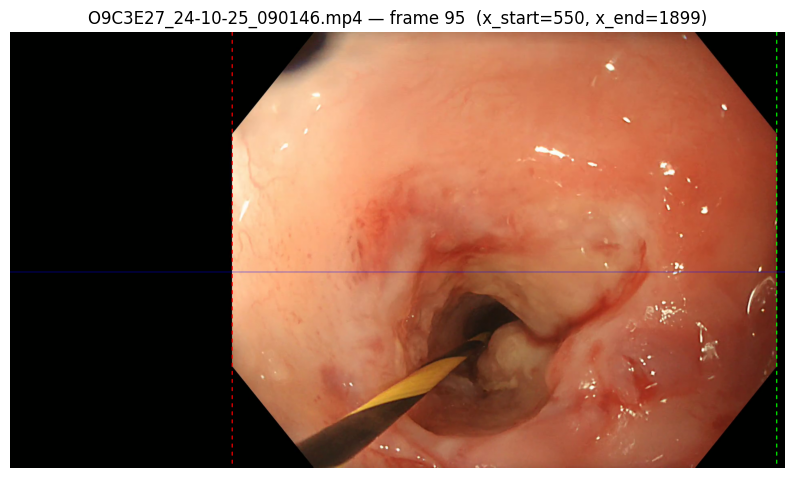

  frame 119: x_start=550  x_end=1899  | left baseline=1  right baseline=1


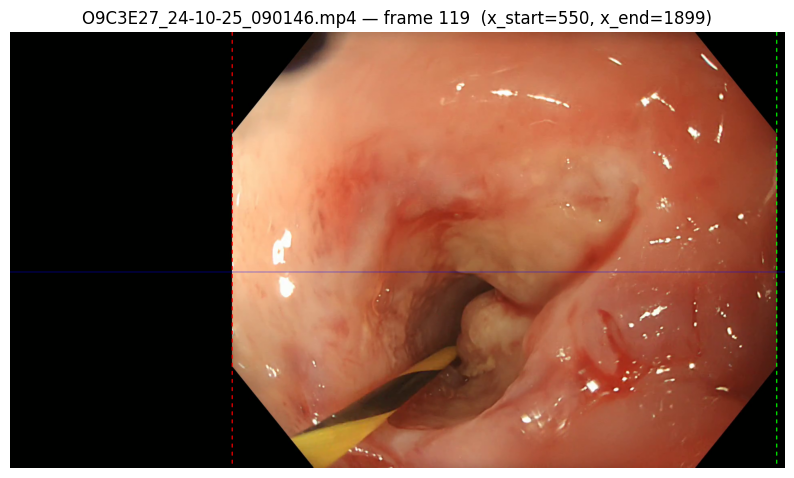

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\O9E3CEC_07-01-26_092102.mp4
  frame 686: x_start=550  x_end=1899  | left baseline=16  right baseline=16


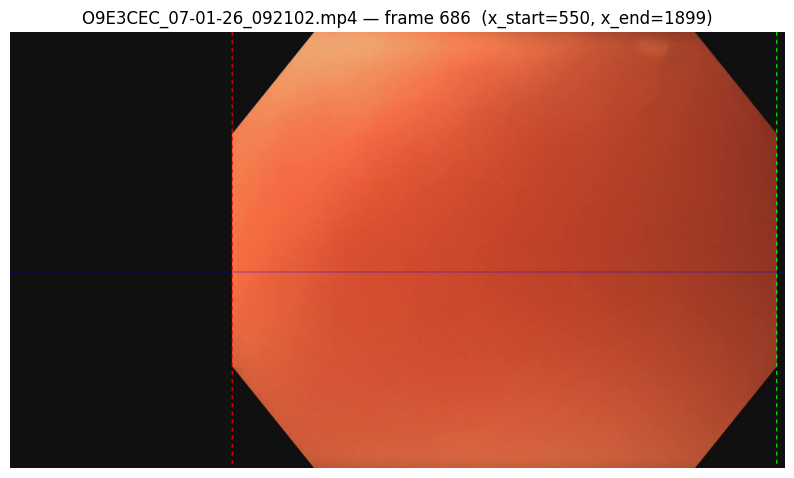

  frame 858: x_start=550  x_end=1899  | left baseline=16  right baseline=16


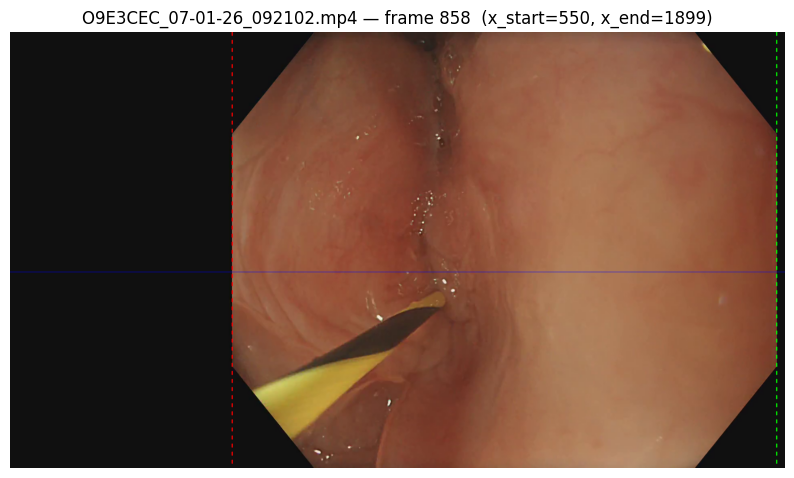

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA08324_23-03-26_102243.mp4
  frame 301: x_start=550  x_end=1899  | left baseline=0  right baseline=0


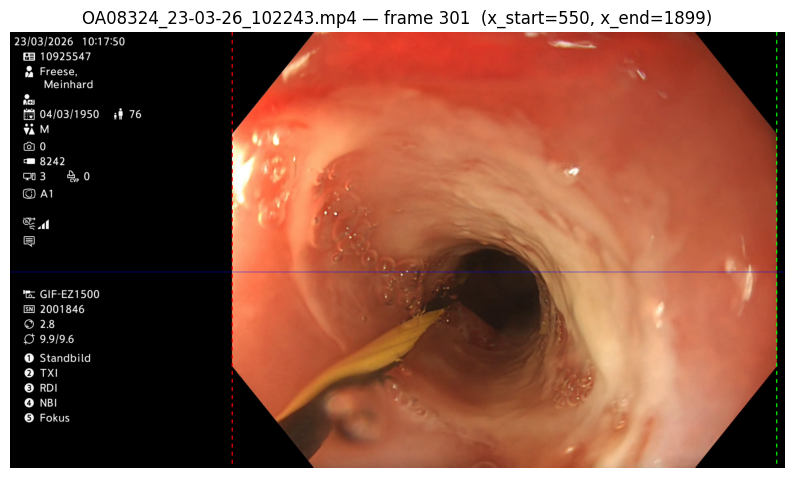

  frame 377: x_start=550  x_end=1899  | left baseline=0  right baseline=0


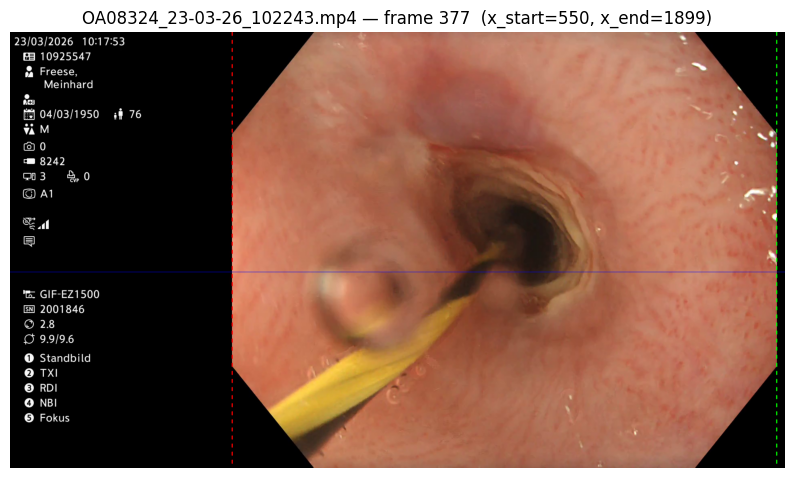

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA2459C_05-05-26_102237.mp4
  frame 436: x_start=550  x_end=1899  | left baseline=15  right baseline=15


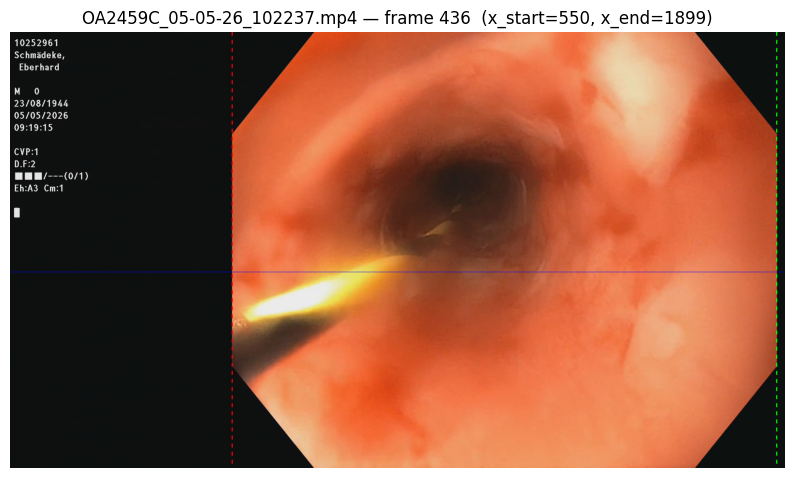

  frame 545: x_start=550  x_end=1899  | left baseline=16  right baseline=15


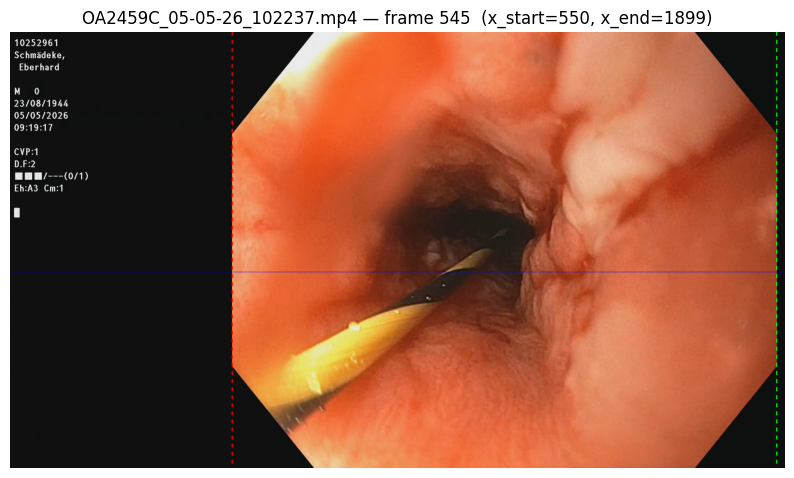

Video: C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos\OA245A0_05-05-26_102303.mp4
  frame 518: x_start=550  x_end=1899  | left baseline=16  right baseline=15


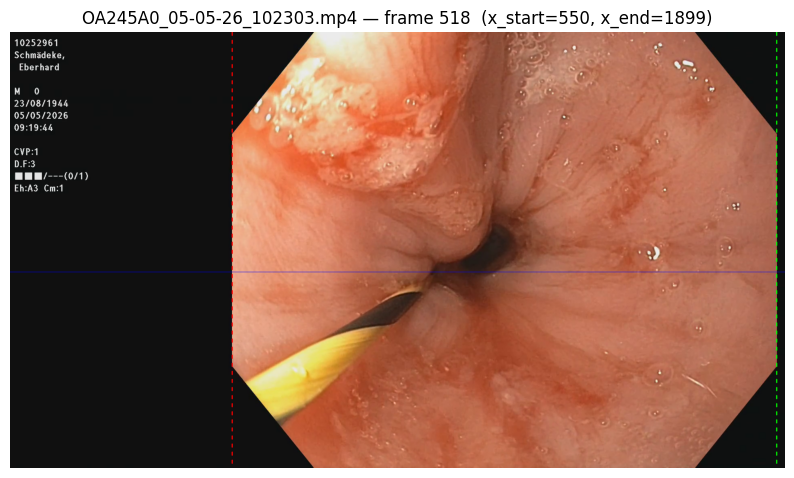

  frame 647: x_start=550  x_end=1899  | left baseline=16  right baseline=15


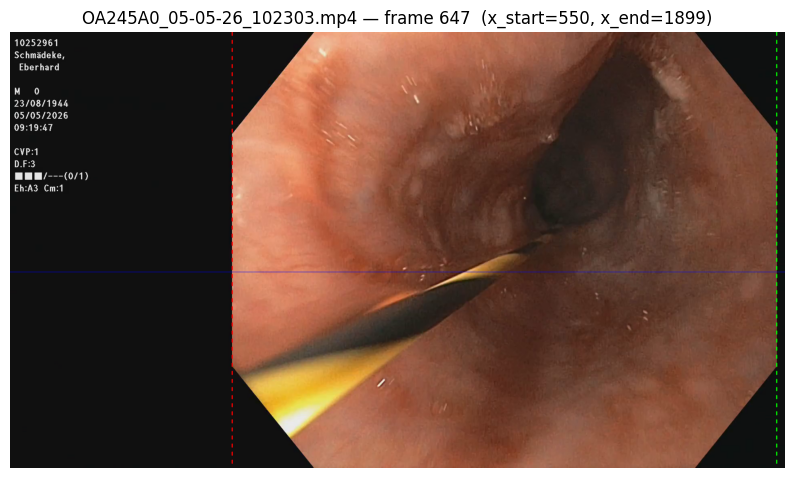


SUMMARY across all videos/frames
  x_start values: [550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550, 550]
  x_end values:   [1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899, 1899]

  Safest fixed crop (never cuts content):
    x_start (leftmost observed)  = 550
    x_end   (rightmost observed) = 1899


In [48]:
# ---------- CONFIG ----------
video_folder = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\Selected_videos"
video_extensions = ("*.mp4", "*.avi", "*.mov", "*.mkv")

scan_row_frac   = 0.55
baseline_window = 5     # first/last N pixels used to establish the black baseline
delta_thresh    = 20    # edge = first pixel whose value differs from baseline by more than this

# ---------- HELPERS ----------

def find_roi_horizontal_bounds_delta(frame, scan_row_frac=0.60, baseline_window=5, delta_thresh=20):
    h, w = frame.shape[:2]
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    row_y = int(h * scan_row_frac)
    row = gray[row_y, :].astype(int)

    left_baseline = int(np.median(row[:baseline_window]))
    right_baseline = int(np.median(row[-baseline_window:]))

    x_start = None
    for x in range(w):
        if abs(int(row[x]) - left_baseline) > delta_thresh:
            x_start = x
            break

    x_end = None
    for x in range(w - 1, -1, -1):
        if abs(int(row[x]) - right_baseline) > delta_thresh:
            x_end = x
            break

    return x_start, x_end, row_y, left_baseline, right_baseline


def draw_dotted_vline(img, x, color=(0, 0, 255), thickness=2, gap=12, dash=8):
    h = img.shape[0]
    y = 0
    while y < h:
        y2 = min(y + dash, h)
        cv2.line(img, (x, y), (x, y2), color, thickness)
        y += dash + gap


def middle_n(indices, n=7):
    drop = len(indices) - n
    start_drop = drop // 2
    end_drop = drop - start_drop
    return indices[start_drop: len(indices) - end_drop]


# ---------- MAIN ----------

all_x_starts = []
all_x_ends = []

video_paths = []
for ext in video_extensions:
    video_paths.extend(glob.glob(os.path.join(video_folder, "**", ext), recursive=True))

print(f"Found {len(video_paths)} video(s)\n")

for video_path in video_paths:
    print("=" * 80)
    print("Video:", video_path)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("  Could not open — skipping")
        continue

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    if total_frames < 10:
        print(f"  Only {total_frames} frames — skipping")
        cap.release()
        continue

    frames_to_extract = [int(total_frames * i / 10) for i in range(10)]
    middle_frames = middle_n(frames_to_extract, 2)

    for frame_idx in middle_frames:
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()
        if not ret:
            print(f"  frame {frame_idx}: could not read — skipping")
            continue

        x_start, x_end, row_y, left_baseline, right_baseline = find_roi_horizontal_bounds_delta(
            frame, scan_row_frac=scan_row_frac, baseline_window=baseline_window, delta_thresh=delta_thresh
        )

        if x_start is None or x_end is None:
            print(f"  frame {frame_idx}: edge not found — skipping")
            continue

        print(f"  frame {frame_idx}: x_start={x_start}  x_end={x_end}  "
              f"| left baseline={left_baseline}  right baseline={right_baseline}")

        all_x_starts.append(x_start)
        all_x_ends.append(x_end)

        vis = frame.copy()
        draw_dotted_vline(vis, x_start, color=(0, 0, 255))
        draw_dotted_vline(vis, x_end, color=(0, 255, 0))
        cv2.line(vis, (0, row_y), (width - 1, row_y), (255, 0, 0), 1)

        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.title(f"{os.path.basename(video_path)} — frame {frame_idx}  (x_start={x_start}, x_end={x_end})")
        plt.axis("off")
        plt.show()

    cap.release()

# ---------- SUMMARY ----------
print("\n" + "=" * 80)
print("SUMMARY across all videos/frames")
print(f"  x_start values: {all_x_starts}")
print(f"  x_end values:   {all_x_ends}")
if all_x_starts and all_x_ends:
    print(f"\n  Safest fixed crop (never cuts content):")
    print(f"    x_start (leftmost observed)  = {min(all_x_starts)}")
    print(f"    x_end   (rightmost observed) = {max(all_x_ends)}")

### Result

Both methods agree on every sampled frame: **x_start = 550, x_end = 1899**. Finalized in `Decision_Log.md` (Decision 2).


### Final Function

This function will take a frame and crop it to the decided dimensions.

In [1]:
def crop_frame(frame, x_start=550, x_end=1899, expected_width=1920):
    """
    Apply the finalized fixed horizontal crop to a single frame.
    Removes the black surround / patient-data text panel on the left,
    and the black margin on the right.
    """
    h, w = frame.shape[:2]
    if w != expected_width:
        raise ValueError(
            f"Frame width is {w}px, expected {expected_width}px. "
            f"Fixed crop bounds (x_start={x_start}, x_end={x_end}) were derived "
            f"specifically for {expected_width}px-wide frames and may not be valid here — "
            f"re-verify before applying."
        )
    return frame[:, x_start:x_end]

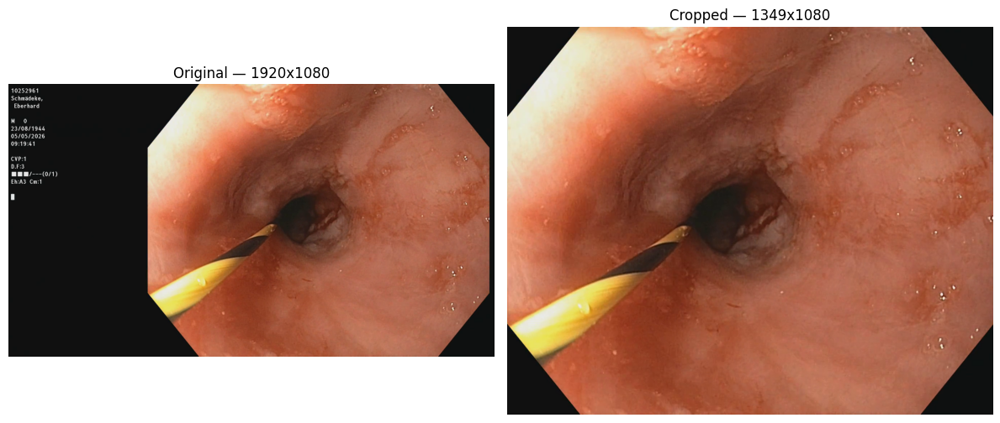

In [4]:
def load_and_crop(image_path):
    frame = cv2.imread(image_path)
    if frame is None:
        raise FileNotFoundError(f"Could not read image at: {image_path}")
    cropped = crop_frame(frame)
    return frame, cropped


# ---------- CONFIG ----------
image_path = "C:/Users/ahmed/Documents/Jobs/Klinikum Oldenburg/sample_frames/frame_0388.png"

original, cropped = load_and_crop(image_path)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title(f"Original — {original.shape[1]}x{original.shape[0]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
plt.title(f"Cropped — {cropped.shape[1]}x{cropped.shape[0]}")
plt.axis("off")

plt.tight_layout()
plt.show()